In [3]:
!pip -q install scikit-learn pandas matplotlib seaborn pillow tqdm


In [4]:
import os
import tarfile
import requests
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
from collections import Counter, defaultdict

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: True


In [5]:
DATA_DIR = "/content/landmark_project"
os.makedirs(DATA_DIR, exist_ok=True)

CSV_URL = "https://s3.amazonaws.com/google-landmark/metadata/train.csv"
CSV_PATH = os.path.join(DATA_DIR, "train.csv")

if not os.path.exists(CSV_PATH):
    response = requests.get(CSV_URL, timeout=120)
    response.raise_for_status()

    with open(CSV_PATH, "wb") as f:
        f.write(response.content)

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (4132914, 3)
Columns: ['id', 'url', 'landmark_id']


,id,url,landmark_id
0,6e158a47eb2ca3f6,https://upload.wikimedia.org/wikipedia/commons...,142820
1,202cd79556f30760,http://upload.wikimedia.org/wikipedia/commons/...,104169
2,3ad87684c99c06e1,http://upload.wikimedia.org/wikipedia/commons/...,37914
3,e7f70e9c61e66af3,https://upload.wikimedia.org/wikipedia/commons...,102140
4,4072182eddd0100e,https://upload.wikimedia.org/wikipedia/commons...,2474


In [6]:
ARCHIVE_PATH = os.path.join(DATA_DIR, "images_000.tar")
ARCHIVE_URL = "https://s3.amazonaws.com/google-landmark/train/images_000.tar"

if not os.path.exists(ARCHIVE_PATH):
    with requests.get(
        ARCHIVE_URL, stream=True, timeout=(30, 300)
    ) as response:
        response.raise_for_status()

        with open(ARCHIVE_PATH, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

print("Archive downloaded:", os.path.getsize(ARCHIVE_PATH) / 1e9, "GB")

Archive downloaded: 1.067018752 GB


In [7]:
# Identify the required metadata columns
columns = {c.lower(): c for c in df.columns}

if "id" not in columns or "landmark_id" not in columns:
    raise ValueError(
        f"Expected id and landmark_id columns. Found: {df.columns.tolist()}"
    )

id_col = columns["id"]
label_col = columns["landmark_id"]

df[id_col] = df[id_col].astype(str)
label_map = dict(zip(df[id_col], df[label_col]))

print("Scanning archive. This can take a few minutes...")

records = []

with tarfile.open(ARCHIVE_PATH, "r:") as tar:
    for member in tqdm(tar):
        if not member.isfile():
            continue

        filename = os.path.basename(member.name)

        if not filename.lower().endswith((".jpg", ".jpeg")):
            continue

        image_id = os.path.splitext(filename)[0]

        if image_id in label_map:
            records.append({
                "id": image_id,
                "label": str(label_map[image_id]),
                "member": member.name
            })

print("Matched images:", len(records))

if len(records) == 0:
    raise RuntimeError(
        "No matching images found. Check the CSV schema and archive contents."
    )

counts = Counter(r["label"] for r in records)
print("Number of represented landmark classes:", len(counts))
print("Most frequent classes:", counts.most_common(10))

Scanning archive. This can take a few minutes...


0it [00:00, ?it/s]

Matched images: 8266
Number of represented landmark classes: 7444
Most frequent classes: [('138982', 25), ('62798', 11), ('171772', 8), ('83144', 8), ('45428', 7), ('176528', 6), ('1924', 5), ('126637', 5), ('187209', 5), ('2079', 5)]


In [8]:
MIN_IMAGES_PER_CLASS = 5
MAX_CLASSES = 5
MAX_IMAGES_PER_CLASS = 40

eligible = [
    (label, count)
    for label, count in counts.items()
    if count >= MIN_IMAGES_PER_CLASS
]

eligible.sort(key=lambda x: x[1], reverse=True)
selected_classes = {label for label, _ in eligible[:MAX_CLASSES]}

if len(selected_classes) < 2:
    raise RuntimeError(
        "The archive contains too few suitable classes. "
        "Use another archive or a different dataset source."
    )

IMAGE_DIR = os.path.join(DATA_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

selected_records = []
per_class = Counter()

for record in records:
    label = record["label"]

    if label not in selected_classes:
        continue

    if per_class[label] >= MAX_IMAGES_PER_CLASS:
        continue

    selected_records.append(record)
    per_class[label] += 1

print("Selected classes:", sorted(selected_classes))
print("Images to extract:", len(selected_records))

# Extract only the selected images
with tarfile.open(ARCHIVE_PATH, "r:") as tar:
    for record in tqdm(selected_records):
        label_dir = os.path.join(IMAGE_DIR, record["label"])
        os.makedirs(label_dir, exist_ok=True)

        output_path = os.path.join(
            label_dir, record["id"] + ".jpg"
        )

        if os.path.exists(output_path):
            continue

        source = tar.extractfile(record["member"])

        if source is None:
            continue

        try:
            with Image.open(source) as img:
                img.convert("RGB").save(output_path, "JPEG")
        except Exception:
            continue

# Count successfully extracted images
image_paths, image_labels = [], []

for label in sorted(selected_classes):
    folder = os.path.join(IMAGE_DIR, label)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, filename))
            image_labels.append(label)

print("Successfully extracted:", len(image_paths))
print("Class counts:", Counter(image_labels))

Selected classes: ['138982', '171772', '45428', '62798', '83144']
Images to extract: 59


  0%|          | 0/59 [00:00<?, ?it/s]

Successfully extracted: 59
Class counts: Counter({'138982': 25, '62798': 11, '171772': 8, '83144': 8, '45428': 7})


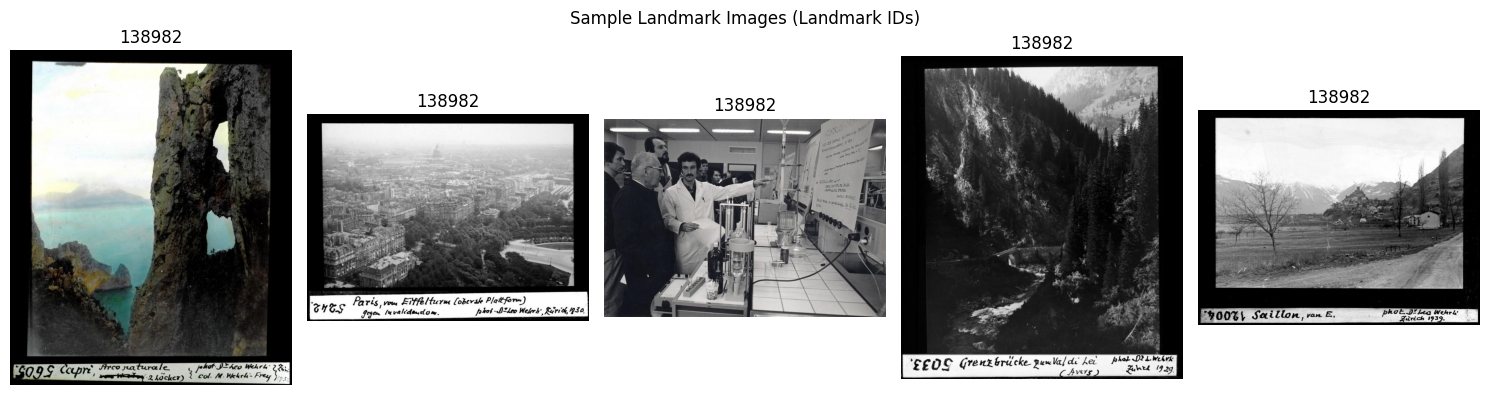

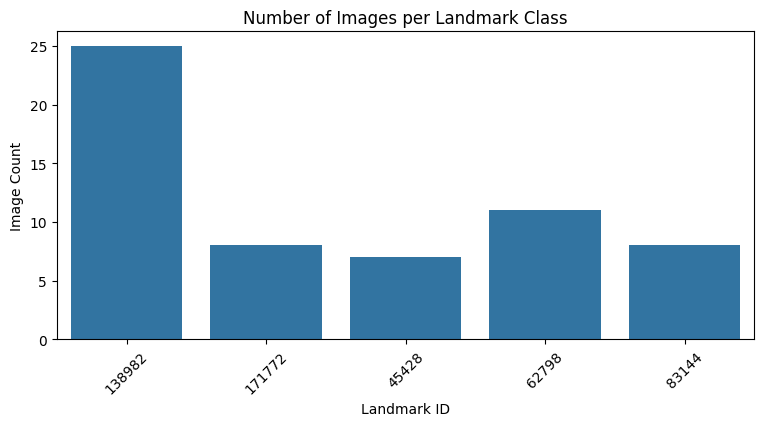

In [9]:
fig, axes = plt.subplots(1, min(5, len(image_paths)), figsize=(15, 4))
axes = np.atleast_1d(axes)

for ax, path in zip(axes, image_paths[:5]):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(os.path.basename(os.path.dirname(path)))
    ax.axis("off")

plt.suptitle("Sample Landmark Images (Landmark IDs)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.countplot(x=image_labels, order=sorted(set(image_labels)))
plt.title("Number of Images per Landmark Class")
plt.xlabel("Landmark ID")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.show()

In [10]:
class_names = sorted(set(image_labels))
class_to_index = {name: i for i, name in enumerate(class_names)}

X = np.array(image_paths)
y = np.array([class_to_index[label] for label in image_labels])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20,
    random_state=SEED, stratify=y_train
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Landmark classes:", class_names)

Training images: 37
Validation images: 10
Test images: 12
Landmark classes: ['138982', '171772', '45428', '62798', '83144']


In [11]:
IMG_SIZE = 160
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.shuffle(len(paths), seed=SEED)

    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print("Data pipeline ready.")

Data pipeline ready.


In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
])

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
EPOCHS = 8

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(DATA_DIR, "best_landmark_model.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.2162 - loss: 2.4280 - val_accuracy: 0.6000 - val_loss: 1.2389
Epoch 2/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 476ms/step - accuracy: 0.2432 - loss: 1.7563 - val_accuracy: 0.6000 - val_loss: 1.1609
Epoch 3/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 349ms/step - accuracy: 0.4324 - loss: 1.2538 - val_accuracy: 0.5000 - val_loss: 1.1268
Epoch 4/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 333ms/step - accuracy: 0.5946 - loss: 0.8815 - val_accuracy: 0.6000 - val_loss: 1.0652
Epoch 5/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 336ms/step - accuracy: 0.6757 - loss: 0.7898 - val_accuracy: 0.7000 - val_loss: 0.9893
Epoch 6/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 432ms/step - accuracy: 0.7838 - loss: 0.5874 - val_accuracy: 0.7000 - val_loss: 0.9147
Epoch 7/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 422ms/step - accuracy: 0.8108 - loss: 0.4489 - val_accuracy: 0.7000 - val_loss: 0.8330
Epoch 8/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 339ms/step - accuracy: 0.8108 - loss: 0.3876 - val_accuracy: 0.7000 - val_loss: 0.7337


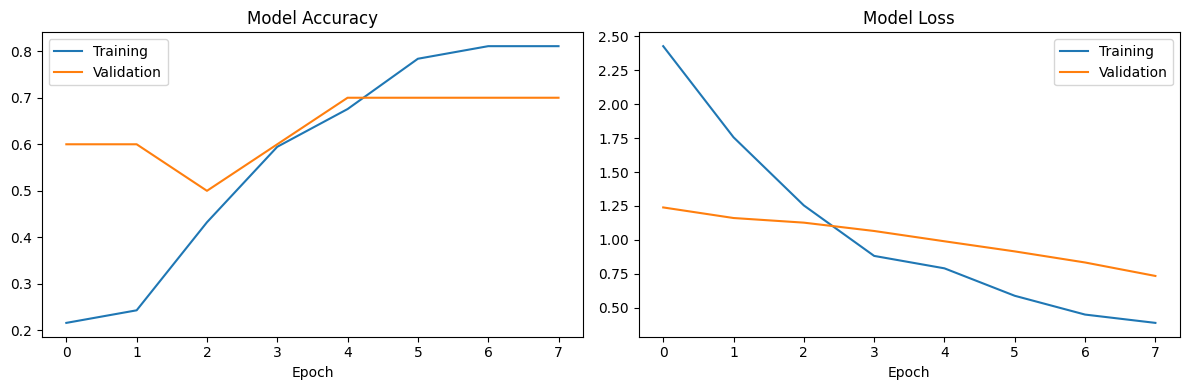

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Accuracy : 0.6667
Precision: 0.5250
Recall   : 0.5000
F1-score : 0.4872
\nDetailed classification report:
              precision    recall  f1-score   support

      138982       0.62      1.00      0.77         5
      171772       1.00      0.50      0.67         2
       45428       0.00      0.00      0.00         1
       62798       1.00      1.00      1.00         2
       83144       0.00      0.00      0.00         2

    accuracy                           0.67        12
   macro avg       0.53      0.50      0.49        12
weighted avg       0.59      0.67      0.60        12



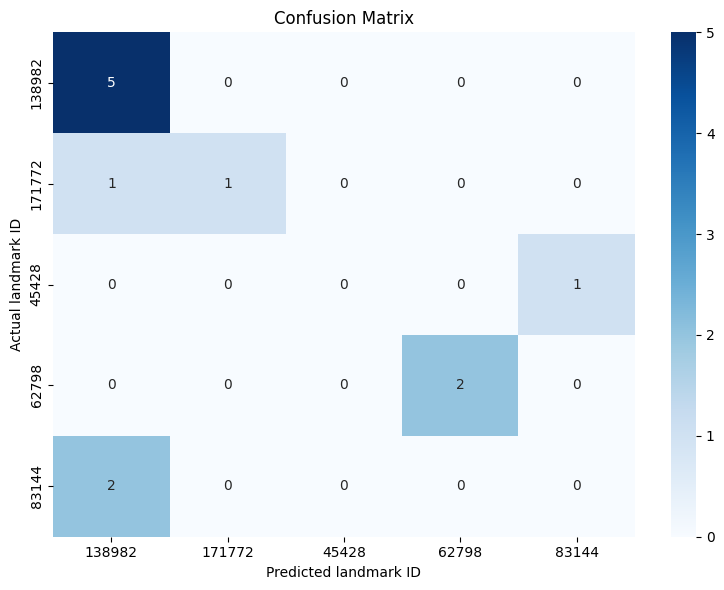

In [15]:
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")

print("\\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_test, y_pred, labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted landmark ID")
plt.ylabel("Actual landmark ID")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

Actual landmark ID: 171772


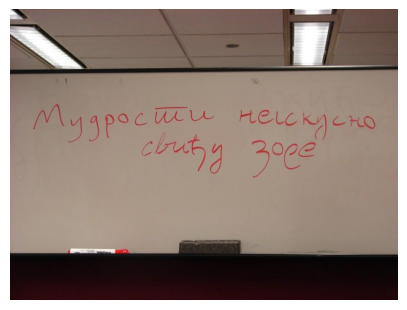

Top predictions:
Landmark ID 138982: 57.88%
Landmark ID 83144: 21.98%
Landmark ID 45428: 10.54%
Actual landmark ID: 138982


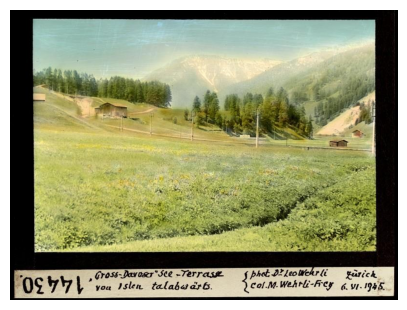

Top predictions:
Landmark ID 138982: 88.24%
Landmark ID 62798: 5.33%
Landmark ID 45428: 3.42%
Actual landmark ID: 171772


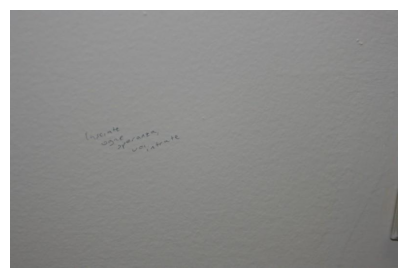

Top predictions:
Landmark ID 171772: 50.31%
Landmark ID 138982: 31.37%
Landmark ID 62798: 15.57%
Actual landmark ID: 138982


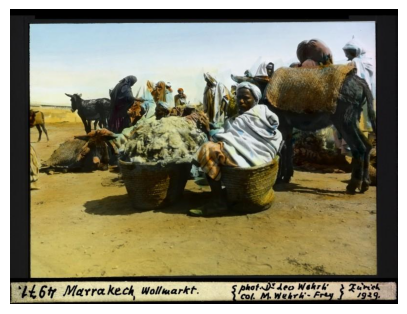

Top predictions:
Landmark ID 138982: 92.64%
Landmark ID 62798: 3.67%
Landmark ID 45428: 3.04%
Actual landmark ID: 138982


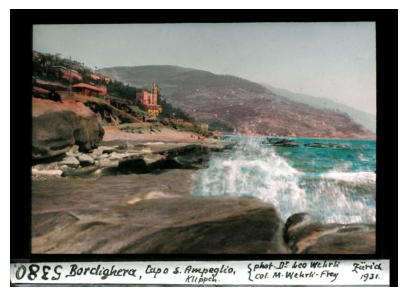

Top predictions:
Landmark ID 138982: 92.11%
Landmark ID 83144: 4.43%
Landmark ID 62798: 1.49%


In [16]:
def predict_landmark(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    arr = np.array(img, dtype=np.float32)
    probabilities = model.predict(arr[None, ...], verbose=0)[0]

    top_indices = np.argsort(probabilities)[::-1][:3]

    plt.figure(figsize=(5, 4))
    plt.imshow(Image.open(image_path).convert("RGB"))
    plt.axis("off")
    plt.show()

    print("Top predictions:")
    for idx in top_indices:
        print(
            f"Landmark ID {class_names[idx]}: "
            f"{probabilities[idx] * 100:.2f}%"
        )

for i in range(min(5, len(X_test))):
    print("Actual landmark ID:", class_names[y_test[i]])
    predict_landmark(X_test[i])

Saving Screenshot 2026-10-17 215630.png to Screenshot 2026-10-17 215630.png


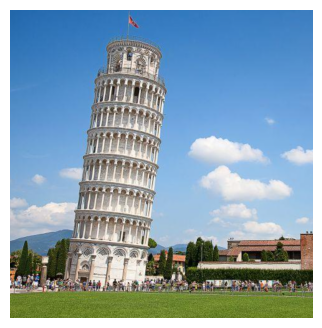

Top predictions:
Landmark ID 45428: 49.90%
Landmark ID 138982: 25.92%
Landmark ID 83144: 14.20%


In [17]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded:
    predict_landmark(filename)

Saving Screenshot 2026-10-17 210613.png to Screenshot 2026-10-17 210613.png
Saving Screenshot 2026-10-17 215557.png to Screenshot 2026-10-17 215557 (1).png
Saving Screenshot 2026-10-17 215611.png to Screenshot 2026-10-17 215611.png
Saving Screenshot 2026-10-17 215621.png to Screenshot 2026-10-17 215621.png
Saving Screenshot 2026-10-17 215630.png to Screenshot 2026-10-17 215630 (1).png

Testing image: Screenshot 2026-10-17 210613.png


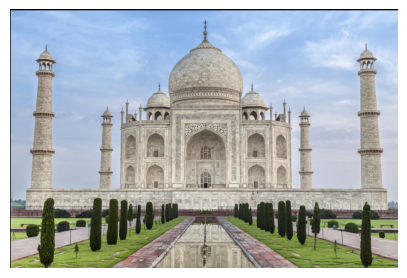

Top predictions:
Landmark ID 45428: 34.66%
Landmark ID 138982: 27.83%
Landmark ID 62798: 15.75%

Testing image: Screenshot 2026-10-17 215557 (1).png


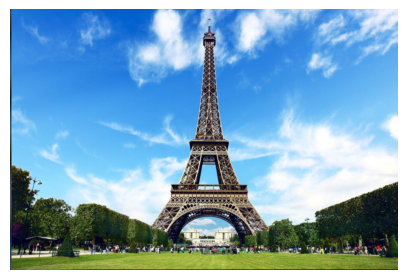

Top predictions:
Landmark ID 138982: 83.39%
Landmark ID 83144: 8.57%
Landmark ID 171772: 3.47%

Testing image: Screenshot 2026-10-17 215611.png


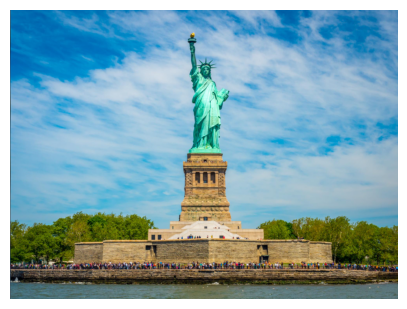

Top predictions:
Landmark ID 45428: 30.19%
Landmark ID 138982: 29.24%
Landmark ID 62798: 23.25%

Testing image: Screenshot 2026-10-17 215621.png


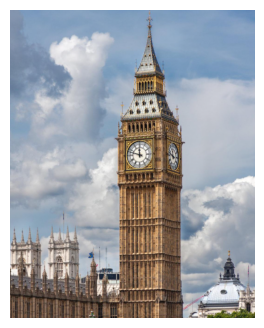

Top predictions:
Landmark ID 138982: 43.23%
Landmark ID 45428: 27.94%
Landmark ID 171772: 15.87%

Testing image: Screenshot 2026-10-17 215630 (1).png


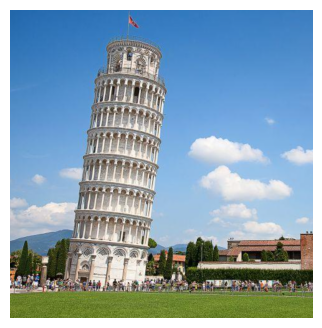

Top predictions:
Landmark ID 45428: 49.90%
Landmark ID 138982: 25.92%
Landmark ID 83144: 14.20%


In [18]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded:
    print("\nTesting image:", filename)
    predict_landmark(filename)

In [19]:
print("Training accuracy:", history.history["accuracy"][-1])
print("Validation accuracy:", history.history["val_accuracy"][-1])

Training accuracy: 0.8108108043670654
Validation accuracy: 0.699999988079071


In [20]:
model.save("/content/landmark_model.keras")

In [21]:
from google.colab import files
files.download("/content/landmark_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>